# Phase 2 — Temporal CNN (07)

Issue #59. The temporal CNN (Bai, Kolter and Koltun, 2018) reads the window with dilated causal convolutions in residual blocks. *Causal* means the output at cycle t only uses cycles up to t. Dilation doubles at each level, so the **receptive field** (how many cycles the last output can see) grows exponentially with depth: `1 + 2(k − 1)(2^L − 1)` for kernel size k and L levels. Unlike the LSTM's memory, this field is explicit and can be checked against the 30-cycle window.

**Protocol** (`CONTRIBUTING.md` §8, shared trainer from #53):

- The same 3 engine-grouped folds as Phase 1 (seed 42).
- Inside each fold, 20% of the training engines are held out for early stopping only.
- Training labels are capped at 125, the cap #55 chose from training engines. These runs used 125 before #55 closed, and its choice kept it, so they stand as they are.
- Every held-out cycle is scored against the true, uncapped RUL.
- The **selection metric** is the RMSE on held-out cycles whose true RUL is at most K = 130, the threshold #55 set from training engines. Each run's held-out predictions are kept, so the metric can be recomputed for another K.

**Cross-validation only.** The official test set isn't read here. It runs once, after the model freeze, in #71.

In [1]:
from itertools import product
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rul.data.load import load_subset
from rul.models.registry import build_model
from rul.training.config import apply_overrides, load_config, run_cv
from rul.training.runs import save_cv

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
GRID_DIR = ROOT / "results/models/grids/tcn"  # per-run cache (gitignored); delete it to rerun the grid
FIGURES = ROOT / "results/figures"

train = load_subset("FD001", data_dir=ROOT / "data/raw/CMAPSSData").train
base = load_config(ROOT / "configs/tcn.yaml")
print(f"{train['unit'].nunique()} training engines, {len(train):,} cycles")
print({k: base[k] for k in ("target", "selection", "cv", "inputs", "training")})

100 training engines, 20,631 cycles
{'target': {'cap': 125}, 'selection': {'max_true_rul': 130}, 'cv': {'n_splits': 3, 'split_seed': 42, 'holdout_size': 0.2}, 'inputs': {'type': 'windows', 'window': 30, 'stride': 1, 'n_regimes': 1, 'include_cycle': False}, 'training': {'epochs': 100, 'batch_size': 256, 'learning_rate': 0.001, 'weight_decay': 0.0, 'grad_clip': 1.0, 'scheduler': 'cosine', 'patience': 10, 'loss': 'mse', 'device': 'cpu', 'seed': 42}}


## 1. Grid

Channels (32 or 64), kernel size and depth, and dropout (0.1 or 0.3). Only (kernel, levels) pairs whose receptive field covers the 30-cycle window are tried: (3, 4) sees 61 cycles, (5, 3) sees 57 and (5, 4) sees 121. (3, 3) sees only 29 cycles, one short of the window, so it's left out.

Everything else stays at the shared base settings: window 30, Adam at 1e-3, batch 256, cosine schedule over at most 100 epochs, and patience 10. Each setting is cross-validated on the 3 folds and cached under `results/models/grids/tcn/`, so rerunning the notebook reuses finished runs. A full run is deterministic for a given seed.

In [2]:
from rul.models.tcn import receptive_field

GRID = [
    {"channels": channels, "kernel_size": k, "levels": levels, "dropout": dropout}
    for channels, (k, levels), dropout in product((32, 64), ((3, 4), (5, 3), (5, 4)), (0.1, 0.3))
]
assert all(receptive_field(p["kernel_size"], p["levels"]) >= base["inputs"]["window"] for p in GRID)


def run_key(params: dict) -> str:
    return "_".join(f"{k}{v}" for k, v in params.items())


def cached_cv(params: dict) -> dict:
    """Cross-validate one setting, or load it if it already ran."""
    path = GRID_DIR / f"{run_key(params)}.json"
    if not path.exists():
        config = apply_overrides(base, [f"model.{k}={v}" for k, v in params.items()])
        cv = run_cv(config, train)
        GRID_DIR.mkdir(parents=True, exist_ok=True)
        cv.predictions.to_csv(path.with_suffix(".csv"), index=False)
        path.write_text(json.dumps({"params": params, **cv.to_dict()}))
    return json.loads(path.read_text())


def model_of(params: dict):
    return build_model({"type": "tcn", **params}, {"n_features": 15})


grid_runs = [cached_cv(params) for params in GRID]
grid = pd.DataFrame([
    {**run["params"],
     **{"receptive_field": receptive_field(run["params"]["kernel_size"], run["params"]["levels"])},
     "parameters": sum(w.numel() for w in model_of(run["params"]).parameters()),
     "selection_rmse": run["summary"]["selection_rmse"]["mean"],
     "selection_std": run["summary"]["selection_rmse"]["std"],
     "all_cycle_rmse": run["summary"]["rmse"]["mean"],
     "best_epochs": [f["best_epoch"] for f in run["folds"]],
     "minutes": run["seconds"] / 60}
    for run in grid_runs
]).sort_values("selection_rmse").reset_index(drop=True)
grid.to_csv(ROOT / "results/metrics/fd001_tcn_grid.csv", index=False)
display(grid.round(2))

,channels,kernel_size,levels,dropout,receptive_field,parameters,selection_rmse,selection_std,all_cycle_rmse,best_epochs,minutes
0,64,5,4,0.1,121,149761,16.88,0.64,48.13,"[7, 8, 7]",6.63
1,32,5,3,0.3,57,28737,17.10,1.02,48.94,"[20, 11, 22]",4.00
2,32,5,3,0.1,57,28737,17.15,0.42,48.71,"[19, 11, 13]",3.42
3,32,3,4,0.1,61,23745,17.24,1.19,48.66,"[19, 18, 18]",5.12
4,32,5,4,0.3,121,39041,17.39,1.06,49.11,"[17, 16, 29]",6.31
5,64,5,3,0.1,57,108673,17.56,0.53,48.63,"[28, 4, 4]",6.08
6,64,5,4,0.3,121,149761,17.56,0.52,48.38,"[10, 8, 7]",6.87
7,32,5,4,0.1,121,39041,17.67,0.92,48.16,"[8, 8, 8]",3.65
8,64,5,3,0.3,57,108673,17.69,0.54,49.20,"[25, 8, 10]",6.75
9,64,3,4,0.1,61,90497,17.75,1.38,48.59,"[7, 10, 6]",5.93


## 2. Choose the setting

The setting with the lowest mean selection RMSE across the 3 folds sets the bar. A gap smaller than that setting's fold-to-fold standard deviation isn't a real difference, so among the settings within one standard deviation of the best, the one with the fewest parameters is chosen.

In [3]:
PARAMS = ["channels", "kernel_size", "levels", "dropout"]
best = grid.iloc[0]
close = grid[grid["selection_rmse"] <= best["selection_rmse"] + best["selection_std"]]
chosen = close.sort_values(["parameters", "selection_rmse"]).iloc[0]
CHOSEN = {k: (float(chosen[k]) if k == "dropout" else int(chosen[k])) for k in PARAMS}
print(f"lowest selection RMSE: {best['selection_rmse']:.2f} ± {best['selection_std']:.2f} ({best['parameters']:,} parameters)")
print(f"settings within one standard deviation: {len(close)}; chosen (fewest parameters): {CHOSEN}, "
      f"{chosen['selection_rmse']:.2f} ± {chosen['selection_std']:.2f}, {int(chosen['parameters']):,} parameters")

lowest selection RMSE: 16.88 ± 0.64 (149,761 parameters)
settings within one standard deviation: 5; chosen (fewest parameters): {'channels': 32, 'kernel_size': 3, 'levels': 4, 'dropout': 0.1}, 17.24 ± 1.19, 23,745 parameters


## 3. Chosen setting: capped and uncapped targets

The chosen setting is rerun and saved for both targets:

- **Capped at 125:** `results/metrics/fd001_cv_tcn.json`
- **Uncapped:** `fd001_cv_tcn_uncapped.json`

Each run also saves every held-out cycle's prediction (`*_predictions.csv`), for the hybrid study (#68) and validation (#72). The capped rerun has to match its grid run exactly, which checks that the seed fixes the result.

In [4]:
final_config = apply_overrides(base, [f"model.{k}={v}" for k, v in CHOSEN.items()])
runs = {
    "capped at 125": (final_config, "fd001_cv_tcn"),
    "uncapped": (apply_overrides(final_config, ["target.cap=null"]), "fd001_cv_tcn_uncapped"),
}
results = {}
for label, (config, name) in runs.items():
    results[label] = run_cv(config, train)
    save_cv(name, results[label], meta={"name": name, "subset": "FD001", "config": config})

grid_value = grid.loc[(grid[PARAMS] == pd.Series(CHOSEN)).all(axis=1), "selection_rmse"].item()
assert np.isclose(results["capped at 125"].summary()["selection_rmse"]["mean"], grid_value)

rows = []
for label, cv in results.items():
    s = cv.summary()
    rows.append({"target": label,
                 "selection RMSE": f"{s['selection_rmse']['mean']:.2f} ± {s['selection_rmse']['std']:.2f}",
                 "all-cycle RMSE": f"{s['rmse']['mean']:.2f} ± {s['rmse']['std']:.2f}",
                 "all-cycle MAE": f"{s['mae']['mean']:.2f}",
                 "best epochs": [f.best_epoch for f in cv.folds]})
display(pd.DataFrame(rows))

,target,selection RMSE,all-cycle RMSE,all-cycle MAE,best epochs
0,capped at 125,17.24 ± 1.19,48.66 ± 5.18,32.08,"[19, 18, 18]"
1,uncapped,29.93 ± 2.47,42.41 ± 5.48,30.03,"[11, 13, 15]"


**Reading the two targets.** All-cycle RMSE punishes the capped model on early cycles, where the true RUL can be over 300 but the model predicts about 125. The official test hardly scores cycles like that, because test engines are scored at their last cycle. The selection metric only looks at cycles near failure, which is where the test engines are, so it is the fair comparison here. The stage-wise table shows where each target wins (late ≤ 50 < mid ≤ 100 < early, by true RUL).

In [5]:
def stage_rows(cv, label):
    return [{"target": label, "fold": f.fold, "stage": stage, "RMSE": s["rmse"]}
            for f in cv.folds for stage, s in f.scores["all_cycles"]["by_stage"].items()]

stages = pd.DataFrame([r for label, cv in results.items() for r in stage_rows(cv, label)])
display(stages.pivot_table(index="stage", columns="target", values="RMSE", aggfunc="mean")
        .loc[["late", "mid", "early"]].round(2))

target,capped at 125,uncapped
stage,,
late,12.29,17.72
mid,21.66,36.03
early,65.87,52.42


## 4. Learning curves (capped target)

Training RMSE against the early-stopping holdout for each fold. The dashed line is the epoch whose weights are kept.

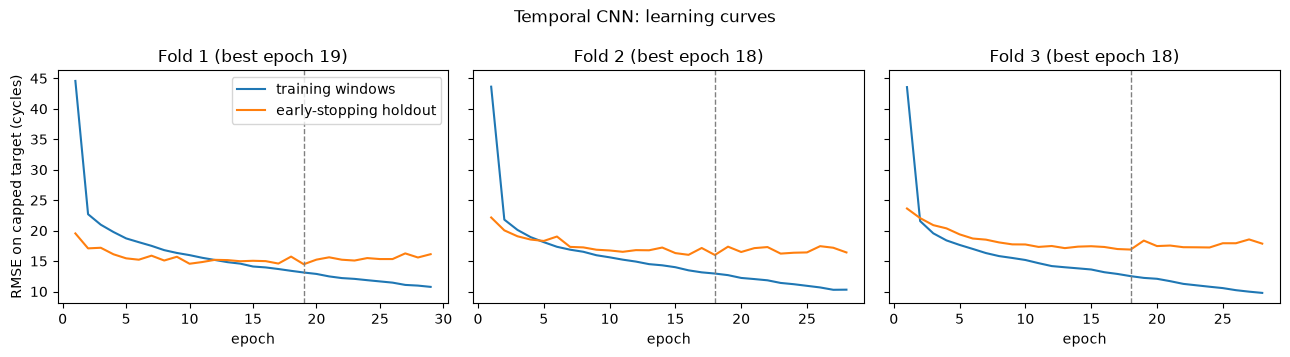

In [6]:
capped = results["capped at 125"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, fold in zip(axes, capped.folds):
    hist = pd.DataFrame(fold.history)
    ax.plot(hist["epoch"], np.sqrt(hist["train_loss"]) * 125, label="training windows")
    ax.plot(hist["epoch"], hist["val_rmse"], label="early-stopping holdout")
    ax.axvline(fold.best_epoch, color="grey", ls="--", lw=1)
    ax.set(title=f"Fold {fold.fold} (best epoch {fold.best_epoch})", xlabel="epoch")
axes[0].set_ylabel("RMSE on capped target (cycles)")
axes[0].legend()
fig.suptitle("Temporal CNN: learning curves")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_tcn_learning_curves.png", dpi=150)
plt.show()

## 5. Held-out predictions

Every held-out cycle, coloured by fold. The shaded band is what the selection metric scores.

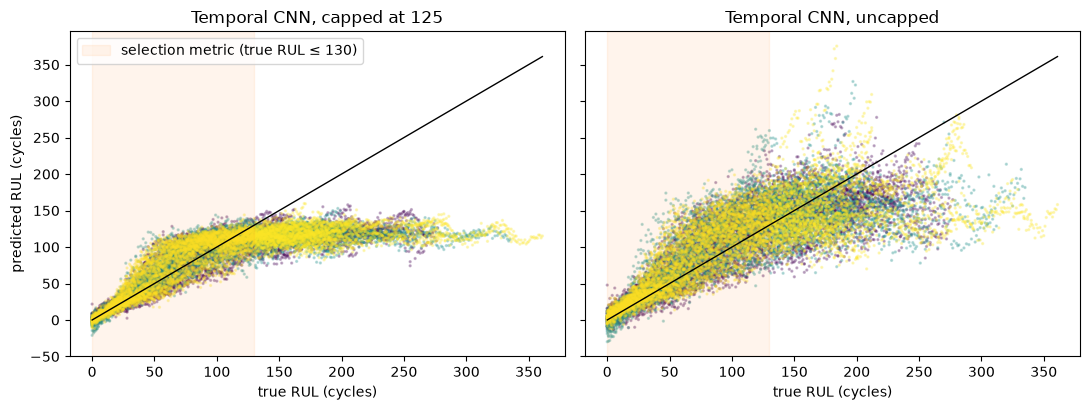

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True, sharey=True)
for ax, (label, cv) in zip(axes, results.items()):
    p = cv.predictions
    ax.scatter(p["rul"], p["prediction"], s=2, alpha=0.25, c=p["fold"], cmap="viridis")
    lim = [0, p["rul"].max()]
    ax.plot(lim, lim, color="black", lw=1)
    ax.axvspan(0, 130, color="tab:orange", alpha=0.08, label="selection metric (true RUL ≤ 130)")
    ax.set(title=f"Temporal CNN, {label}", xlabel="true RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
axes[0].legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "fd001_tcn_heldout_predictions.png", dpi=150)
plt.show()

## 6. Receptive field

`TCNEncoder.receptive_field` is exact. Changing the oldest cycle inside the field changes the embedding, and changing one cycle older than the field doesn't. `tests/test_tcn.py` checks both. With the chosen setting, every cycle of the window reaches the embedding.

In [8]:
encoder = model_of(CHOSEN).encoder
print(f"chosen setting sees {encoder.receptive_field} cycles; window is {base['inputs']['window']}; covers: {encoder.covers(base['inputs']['window'])}")

chosen setting sees 61 cycles; window is 30; covers: True


## Summary

- **Chosen setting:** 32 channels, kernel 3, 4 levels (dilations 1, 2, 4 and 8), dropout 0.1. Selection RMSE 17.24 ± 1.19 over the 3 folds, with 23,745 parameters. Its receptive field of 61 cycles covers the 30-cycle window. The lowest score was 16.88 ± 0.64 (64 channels, kernel 5, 4 levels, 149,761 parameters). Five settings fall within one standard deviation of it, and the smallest is chosen.
- **Not much to tune:** all 12 settings land between 16.88 and 17.96, about the size of the fold spread. Neither width, kernel size, depth nor dropout helped consistently.
- **Against the other encoders:** the TCN is about 1.5 cycles behind the LSTM (15.78) and the Transformer (15.59), mostly near failure, with late-stage RMSE 12.29 against 9.43 and 9.35. These are single-seed scores, and #68 found that a network's score can move by up to about 2 cycles between seeds, so treat the gap as a hint, not a ranking.
- **Target:** capped beats uncapped near failure (selection RMSE 17.24 against 29.93; late-stage RMSE 12.29 against 17.72).
- **Learning curves:** as with the LSTM, training RMSE keeps falling, to about 10. The early-stopping holdout levels off around 15–18 from about epoch 10.
- `configs/tcn.yaml` holds the chosen setting. These are cross-validation scores; the official test runs once, in #71.